In [43]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
import flash_amr_tools

In [44]:
fig_dir = "/home/watanabe/Projects/meerkat_bowshocks/figures"
flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs"

['sod_hdf5_plt_cnt_0019', 'sod_hdf5_plt_cnt_0006', 'sod_hdf5_plt_cnt_0022', 'sod_hdf5_plt_cnt_0034', 'sod_hdf5_plt_cnt_0030', 'sod_hdf5_plt_cnt_0001', 'sod_hdf5_plt_cnt_0032', 'sod_hdf5_plt_cnt_0009', 'sod_hdf5_plt_cnt_0031', 'sod_hdf5_plt_cnt_0007', 'sod_hdf5_plt_cnt_0003', 'sod_hdf5_plt_cnt_0023', 'sod_hdf5_plt_cnt_0017', 'sod_hdf5_plt_cnt_0026', 'sod_hdf5_plt_cnt_0013', 'sod_hdf5_plt_cnt_0035', 'sod_hdf5_plt_cnt_0015', 'sod_hdf5_plt_cnt_0027', 'sod_hdf5_plt_cnt_0025', 'sod_hdf5_plt_cnt_0033', 'sod_hdf5_plt_cnt_0011', 'sod_hdf5_plt_cnt_0028', 'sod_hdf5_plt_cnt_0024', 'sod_hdf5_plt_cnt_0016', 'sod_hdf5_plt_cnt_0029', 'sod_hdf5_plt_cnt_0018', 'sod_hdf5_plt_cnt_0005', 'sod_hdf5_plt_cnt_0004', 'sod_hdf5_plt_cnt_0021', 'sod_hdf5_plt_cnt_0012', 'sod_hdf5_plt_cnt_0010', 'sod_hdf5_plt_cnt_0002', 'sod_hdf5_plt_cnt_0020', 'sod_hdf5_plt_cnt_0008', 'sod_hdf5_plt_cnt_0014', 'sod_hdf5_plt_cnt_0000']
sod_hdf5_plt_cnt_0000
sod_hdf5_plt_cnt_0001
sod_hdf5_plt_cnt_0002
sod_hdf5_plt_cnt_0003
sod_hdf5_pl

(0.01, 10000.0)

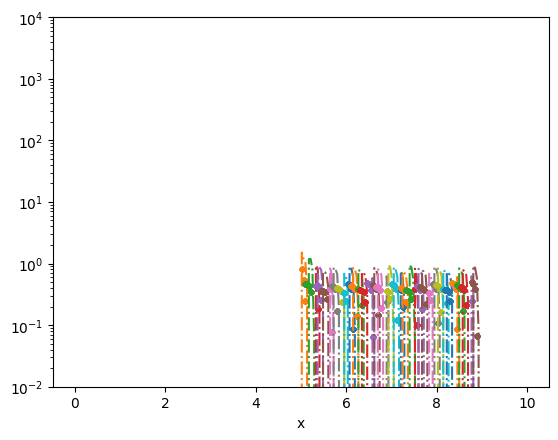

In [45]:
# loop over each file and get the slice
# get list of all files
sim_dir = f"Sod_CRinjection_tmp"
sim_files = []
for file in os.listdir(f"{flash_output_dir}/{sim_dir}"):
    if file.find("plt") < 0 or file.find("forced") > 0:
        continue
    sim_files.append(file)
print(sim_files)

# sort 
sim_files = sorted(sim_files)
for it, sim_file in enumerate(sim_files):
    # if it != 7:
    #     continue
    print(sim_file)
    with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}") as f:
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        time = f["real scalars"][()][0][1]
        dt = f["real scalars"][()][1][1]
        # print(time)

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / 8
        cell_dy = f["block size"][()][:,1] / 8
        cell_dz = f["block size"][()][:,2] / 1
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(1),range(8),range(8), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()
        xsorted_idces = np.argsort(xcoord_arr)

        if time > 0:
            # plt.plot(xcoord_arr[xsorted_idces], np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] + np.mean(f["prcr"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces], color=f"C{it}")
            dens = np.mean(f["dens"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces]

            # plt.plot(xcoord_arr[xsorted_idces], np.mean(f["ener"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] * dens, color=f"C{it}", label="Etot", ls="-")

            # plt.plot(xcoord_arr[xsorted_idces], np.mean(f["eint"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] * dens, color=f"C{it}", label="Eint", ls="--")

            # plt.plot(xcoord_arr[xsorted_idces], np.mean(f["encr"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] * dens, color=f"C{it}", label="Ecr", ls=":")

            plt.plot(xcoord_arr[xsorted_idces], np.mean(f["edis"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] * dens * dt, color=f"C{it}", label="Edis", ls="-.")

            plt.plot(xcoord_arr[xsorted_idces], np.mean(f["einj"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] * dens, color=f"C{it}", label="Einj", ls="", marker="o", ms=3.0)

            if it == 0:
                plt.legend()

plt.xlabel("x")

plt.yscale("log")
plt.ylim(1e-2, 1e4)
# plt.xlim(8.5, 9.5)
# plt.title(rf"Sod MHD test with $\theta_B = {mgob}^\circ$")
# plt.legend(loc="center left")
        # plt.plot(xcoord_arr[xsorted_idces], np.arccos(magx / np.sqrt(magx**2 + magy**2)), color=f"C{it}")

['sod_hdf5_plt_cnt_0019', 'sod_hdf5_plt_cnt_0006', 'sod_hdf5_plt_cnt_0022', 'sod_hdf5_plt_cnt_0034', 'sod_hdf5_plt_cnt_0030', 'sod_hdf5_plt_cnt_0001', 'sod_hdf5_plt_cnt_0032', 'sod_hdf5_plt_cnt_0009', 'sod_hdf5_plt_cnt_0031', 'sod_hdf5_plt_cnt_0007', 'sod_hdf5_plt_cnt_0003', 'sod_hdf5_plt_cnt_0023', 'sod_hdf5_plt_cnt_0017', 'sod_hdf5_plt_cnt_0026', 'sod_hdf5_plt_cnt_0013', 'sod_hdf5_plt_cnt_0035', 'sod_hdf5_plt_cnt_0015', 'sod_hdf5_plt_cnt_0027', 'sod_hdf5_plt_cnt_0025', 'sod_hdf5_plt_cnt_0033', 'sod_hdf5_plt_cnt_0011', 'sod_hdf5_plt_cnt_0028', 'sod_hdf5_plt_cnt_0024', 'sod_hdf5_plt_cnt_0016', 'sod_hdf5_plt_cnt_0029', 'sod_hdf5_plt_cnt_0018', 'sod_hdf5_plt_cnt_0005', 'sod_hdf5_plt_cnt_0004', 'sod_hdf5_plt_cnt_0021', 'sod_hdf5_plt_cnt_0012', 'sod_hdf5_plt_cnt_0010', 'sod_hdf5_plt_cnt_0002', 'sod_hdf5_plt_cnt_0020', 'sod_hdf5_plt_cnt_0008', 'sod_hdf5_plt_cnt_0014', 'sod_hdf5_plt_cnt_0000']


Text(0.5, 0, 'x')

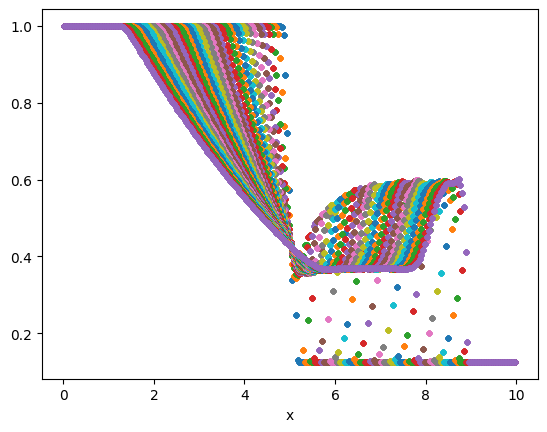

In [46]:
# loop over each file and get the slice
# get list of all files
sim_dir = f"Sod_CRinjection_tmp"
sim_files = []
for file in os.listdir(f"{flash_output_dir}/{sim_dir}"):
    if file.find("plt") < 0 or file.find("forced") > 0:
        continue
    sim_files.append(file)
print(sim_files)

# sort 
sim_files = sorted(sim_files)
for it, sim_file in enumerate(sim_files):
    with h5py.File(f"{flash_output_dir}/{sim_dir}/{sim_file}") as f:
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        time = f["real scalars"][()][0][1]
        # print(time)

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / 8
        cell_dy = f["block size"][()][:,1] / 8
        cell_dz = f["block size"][()][:,2] / 1
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(1),range(8),range(8), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()
        xsorted_idces = np.argsort(xcoord_arr)

        if time > 0:
            # plt.plot(xcoord_arr[xsorted_idces], np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces] + np.mean(f["prcr"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces], color=f"C{it}")
            plt.plot(xcoord_arr[xsorted_idces], np.mean(f["dens"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces], ls="", marker="o", ms=3.0)

plt.xlabel("x")

# plt.yscale("log")
# plt.title(rf"Sod MHD test with $\theta_B = {mgob}^\circ$")
# plt.legend(loc="center left")
        # plt.plot(xcoord_arr[xsorted_idces], np.arccos(magx / np.sqrt(magx**2 + magy**2)), color=f"C{it}")